## EDA

In [27]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['figure.dpi'] = 120

nltk.download('vader_lexicon', quiet=True)

True

### 1. Load Data & Overview

In [2]:
data_path = Path('../data/processed/tracks.parquet')
df = pd.read_parquet(data_path)
df['genres'] = df['genres'].map(lambda g: g[0] if isinstance(g, (list, np.ndarray)) and len(g) > 0 else 'unknown')

In [3]:
print(f"Total Tracks: {len(df):,}")
print(f"Unique Artists: {df['artist'].nunique():,}")
print(f"Canonical Genres: {df['genres'].nunique()}")
print(f"Languages Detected: {df['language'].nunique()}")
df.head(5)

Total Tracks: 4,996
Unique Artists: 1,600
Canonical Genres: 6
Languages Detected: 24


,track_id,title,artist,genres,lyrics_text,language,n_words
0,0017802bf0fc,Bakit Ba Ikaw,Khel Pangilinan,pop,Mula nang aking masilayan Tinataglay mong kaga...,tl,218
1,0020047ac705,8TEEN,Khalid,r&b,Yeah! Ha Yeah! Ha Woke up a little too late th...,en,398
2,003a80d35bb8,땡 Ddaeng,BTS,hip-hop,"Yah, yah 일팔, 일삼, 삼팔, 땡 You wrong, me right, 잘 ...",ko,417
3,005c12563fa9,This Feeling,The Chainsmokers,pop,I'll tell you a story before it tells itself I...,en,336
4,006605f0876f,Burn,Usher,r&b,"Girl, I understand why See, it's burnin' me to...",en,644


In [4]:
df["language"].unique()

<ArrowStringArray>
['tl', 'en', 'ko', 'fr', 'ru', 'it', 'id', 'pt', 'es', 'sw', 'ar', 'tr', 'de',
 'nl', 'ja', 'pl', 'bg', 'so', 'hr', 'pa', 'vi', 'af', 'cy', 'hi']
Length: 24, dtype: str

### 2. Lyrics Length & Token Truncation Analysis
Check effect when truncate at 256 tokens

In [ ]:
percentiles = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
print("Word Count Statistics:")
print(df['n_words'].describe(percentiles=percentiles))

# 1.3 token for a word
token_estimates = df['n_words'] * 1.3
trunc_128 = (token_estimates > 128).mean() * 100
trunc_256 = (token_estimates > 256).mean() * 100
trunc_512 = (token_estimates > 512).mean() * 100

print(f"128 tokens: {trunc_128:.2f}%")
print(f"256 tokens: {trunc_256:.2f}%")
print(f"512 tokens: {trunc_512:.2f}%")

Word Count Statistics:
count     4996.000000
mean       525.015212
std        471.132176
min         30.000000
5%         176.000000
10%        225.000000
25%        320.000000
50%        458.000000
75%        635.250000
90%        823.000000
95%        968.250000
99%       1490.100000
max      13453.000000
Name: n_words, dtype: float64
128 tokens: 99.08%
256 tokens: 92.99%
512 tokens: 61.35%


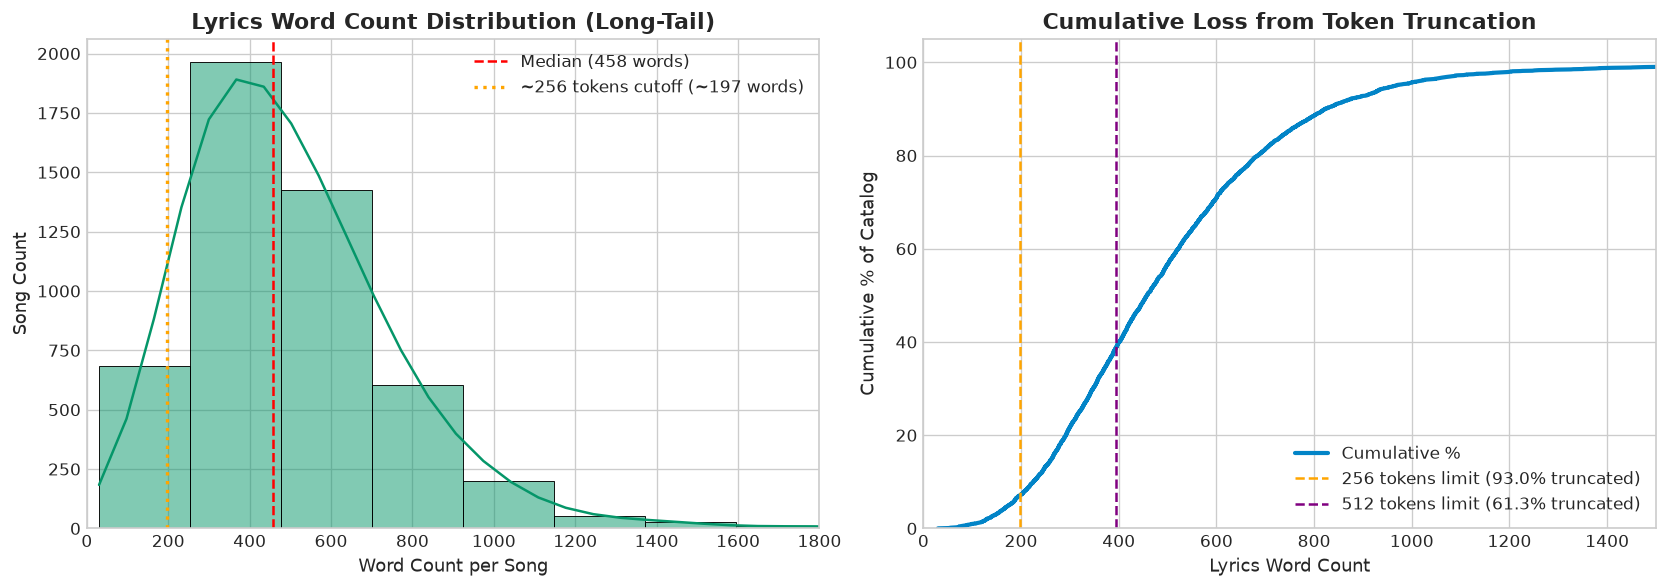

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram & KDE
sns.histplot(df['n_words'], bins=60, kde=True, ax=ax1, color='#059669', edgecolor='black')
ax1.axvline(x=df['n_words'].median(), color='red', linestyle='--', linewidth=1.5, label=f"Median ({df['n_words'].median():.0f} words)")
ax1.axvline(x=197, color='orange', linestyle=':', linewidth=2, label='~256 tokens cutoff (~197 words)')
ax1.set_xlim(0, 1800)
ax1.set_title('Lyrics Word Count Distribution (Long-Tail)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Word Count per Song', fontsize=11)
ax1.set_ylabel('Song Count', fontsize=11)
ax1.legend(loc='upper right')

# Plot 2: Cumulative Distribution
sorted_words = np.sort(df['n_words'])
cdf = np.arange(1, len(sorted_words) + 1) / len(sorted_words) * 100
ax2.plot(sorted_words, cdf, color='#0284c7', linewidth=2.5, label='Cumulative %')
ax2.axvline(x=197, color='orange', linestyle='--', linewidth=1.5, label=f"256 tokens limit ({trunc_256:.1f}% truncated)")
ax2.axvline(x=394, color='purple', linestyle='--', linewidth=1.5, label=f"512 tokens limit ({trunc_512:.1f}% truncated)")
ax2.set_xlim(0, 1500)
ax2.set_ylim(0, 105)
ax2.set_title('Cumulative Loss from Token Truncation', fontsize=13, fontweight='bold')
ax2.set_xlabel('Lyrics Word Count', fontsize=11)
ax2.set_ylabel('Cumulative % of Catalog', fontsize=11)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

### 3. Genre & Language Distribution

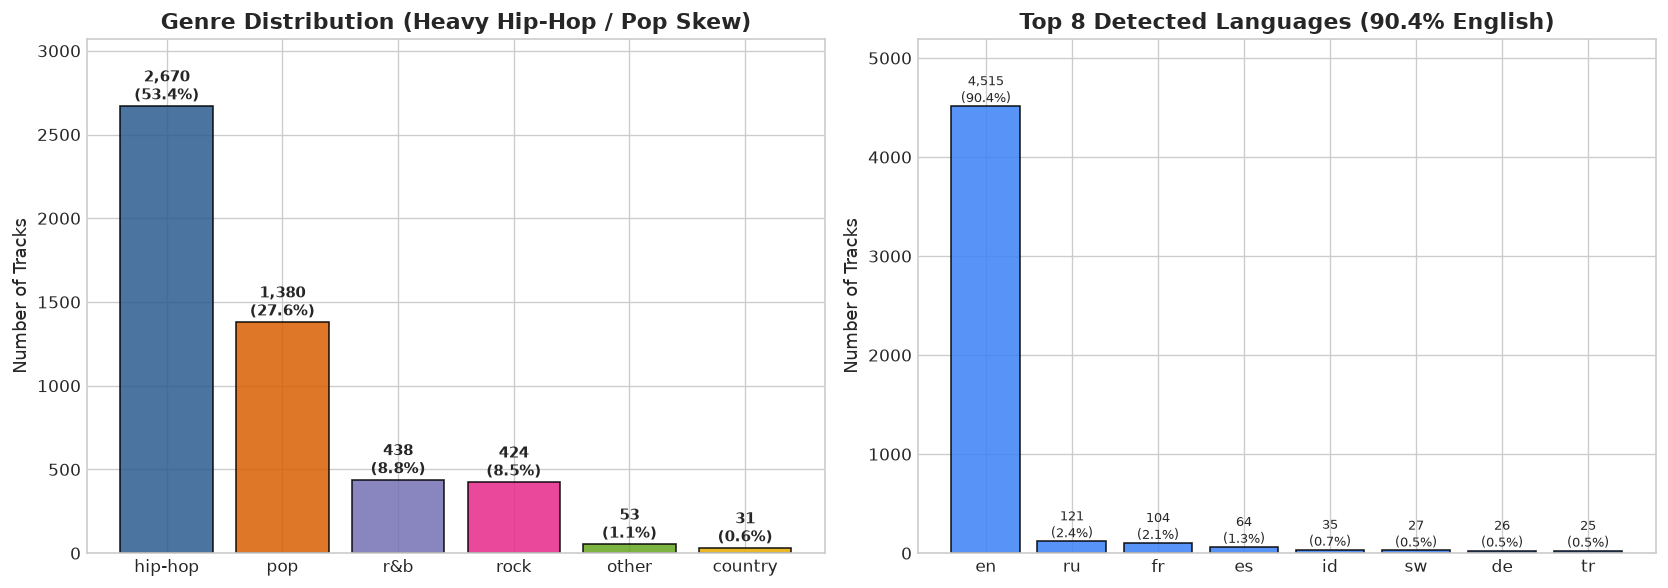

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Genre Distribution
genre_series = df['genres'].value_counts()
colors = ['#2b5c8f', '#d95f02', '#7570b3', '#e7298a', '#66a61e', '#e6ab02']
ax1.bar(genre_series.index, genre_series.values, color=colors[:len(genre_series)], edgecolor='black', alpha=0.85)
for i, v in enumerate(genre_series.values):
    ax1.text(i, v + 40, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontsize=9, fontweight='bold')
ax1.set_title('Genre Distribution (Heavy Hip-Hop / Pop Skew)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Number of Tracks', fontsize=11)
ax1.set_ylim(0, max(genre_series.values) * 1.15)

# Language Distribution
lang_series = df['language'].value_counts().head(8)
ax2.bar(lang_series.index, lang_series.values, color='#3b82f6', edgecolor='black', alpha=0.85)
for i, v in enumerate(lang_series.values):
    ax2.text(i, v + 40, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontsize=8)
ax2.set_title('Top 8 Detected Languages (90.4% English)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Number of Tracks', fontsize=11)
ax2.set_ylim(0, max(lang_series.values) * 1.15)

plt.tight_layout()
plt.show()

### 4. Artist Concentration
check that some artist have many most popular songs

Top 10 artists account for 18.37% of all songs.
Top 20 artists account for 26.62% of all songs.


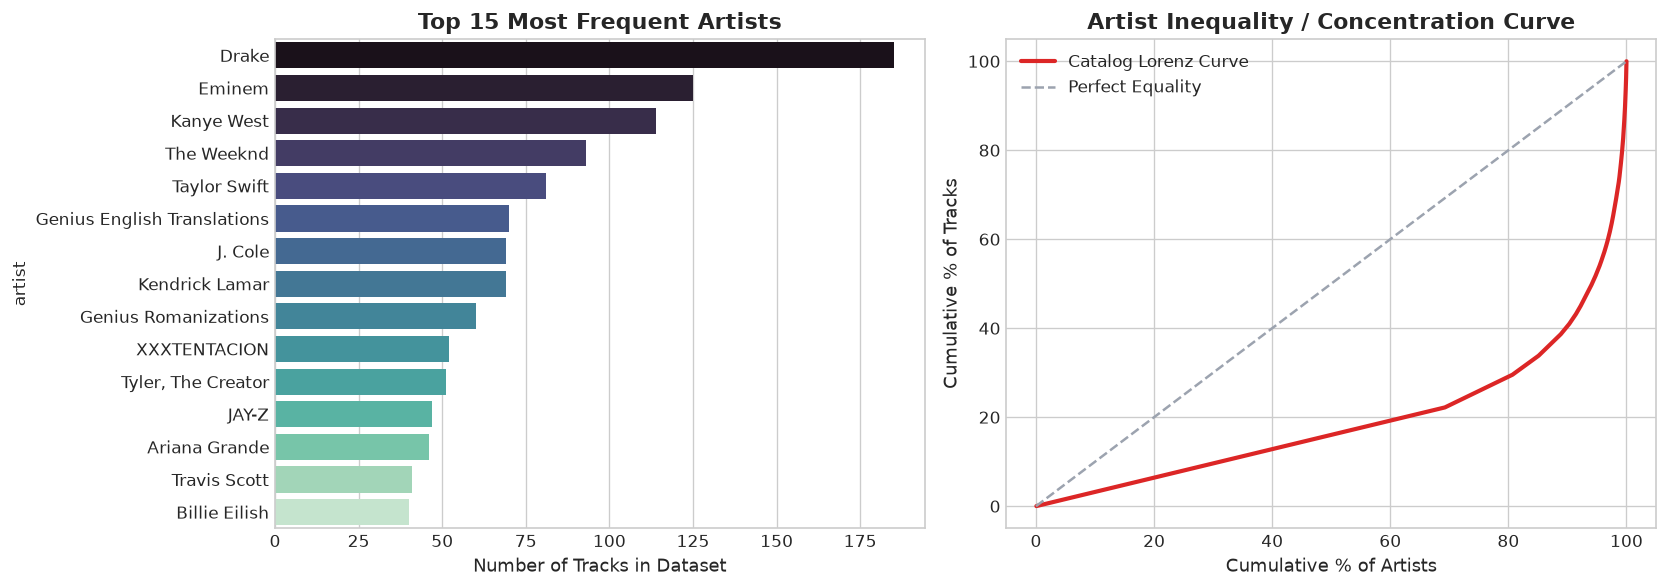

In [24]:
top_artists = df['artist'].value_counts()
top_10_share = (top_artists.head(10).sum() / len(df)) * 100
top_20_share = (top_artists.head(20).sum() / len(df)) * 100
print(f"Top 10 artists account for {top_10_share:.2f}% of all songs.")
print(f"Top 20 artists account for {top_20_share:.2f}% of all songs.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

top_15 = top_artists.head(15)
sns.barplot(x=top_15.values, y=top_15.index, ax=ax1, hue=top_15.index, palette='mako', legend=False)
ax1.set_title('Top 15 Most Frequent Artists', fontsize=13, fontweight='bold')
ax1.set_xlabel('Number of Tracks in Dataset', fontsize=11)

# Lorenz Curve
artist_counts = np.sort(df['artist'].value_counts().values)
cum_artists = np.arange(1, len(artist_counts) + 1) / len(artist_counts) * 100
cum_tracks = np.cumsum(artist_counts) / np.sum(artist_counts) * 100
ax2.plot(cum_artists, cum_tracks, color='#dc2626', linewidth=2.5, label='Catalog Lorenz Curve')
ax2.plot([0, 100], [0, 100], color='#9ca3af', linestyle='--', label='Perfect Equality')
ax2.set_title('Artist Inequality / Concentration Curve', fontsize=13, fontweight='bold')
ax2.set_xlabel('Cumulative % of Artists', fontsize=11)
ax2.set_ylabel('Cumulative % of Tracks', fontsize=11)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

### 5. Sentiment & Emotion Analysis Across Genres
-1 (Negative) is sad, +1 (Possitive) is happy

Sentiment Summary by Genre:
          mean  median    std
genres                       
country  0.366   0.961  0.830
hip-hop -0.190  -0.709  0.854
other    0.068   0.281  0.801
pop      0.340   0.917  0.826
r&b      0.385   0.931  0.817
rock     0.194   0.757  0.859


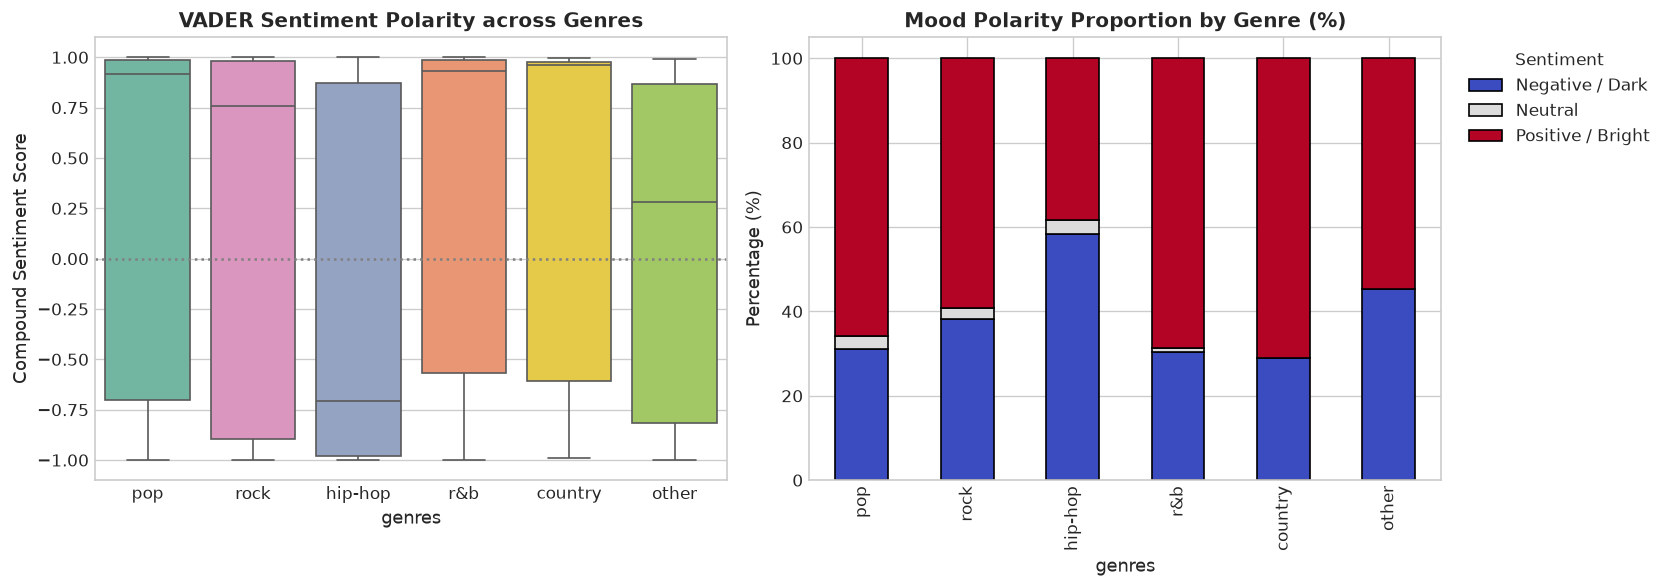

In [25]:
sia = SentimentIntensityAnalyzer()
def get_sentiment(text):
    return sia.polarity_scores(text[:1500])['compound']

df['sentiment_compound'] = df['lyrics_text'].map(get_sentiment)
df['sentiment_class'] = pd.cut(
    df['sentiment_compound'],
    bins=[-1.01, -0.05, 0.05, 1.01],
    labels=['Negative / Dark', 'Neutral', 'Positive / Bright']
)

print("Sentiment Summary by Genre:")
print(df.groupby('genres')['sentiment_compound'].agg(['mean', 'median', 'std']).round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
order = ['pop', 'rock', 'hip-hop', 'r&b', 'country', 'other']

# Boxplot
sns.boxplot(data=df, x='genres', y='sentiment_compound', order=order, ax=ax1, hue='genres', palette='Set2', legend=False)
ax1.set_title('VADER Sentiment Polarity across Genres', fontsize=12, fontweight='bold')
ax1.set_xlabel('genres', fontsize=11)
ax1.set_ylabel('Compound Sentiment Score', fontsize=11)
ax1.axhline(0, color='gray', linestyle=':')

# Stacked Bar
sentiment_counts = df.groupby(['genres', 'sentiment_class'], observed=False).size().unstack(fill_value=0)
sentiment_prop = sentiment_counts.div(sentiment_counts.sum(axis=1), axis=0) * 100
sentiment_prop.loc[order].plot(kind='bar', stacked=True, ax=ax2, colormap='coolwarm', edgecolor='black')
ax2.set_title('Mood Polarity Proportion by Genre (%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('genres', fontsize=11)
ax2.set_ylabel('Percentage (%)', fontsize=11)
ax2.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

sad piano crying
The Crying Game by Nicki Minaj (hip-hop) - Sim: 0.184

workout gym
Gym Class by Lil Peep (hip-hop) - Sim: 0.221

chill romantic r&b love
New Slaves by Kanye West (hip-hop) - Sim: 0.288

raw rap hard bass
All About That Bass by Meghan Trainor (pop) - Sim: 0.344



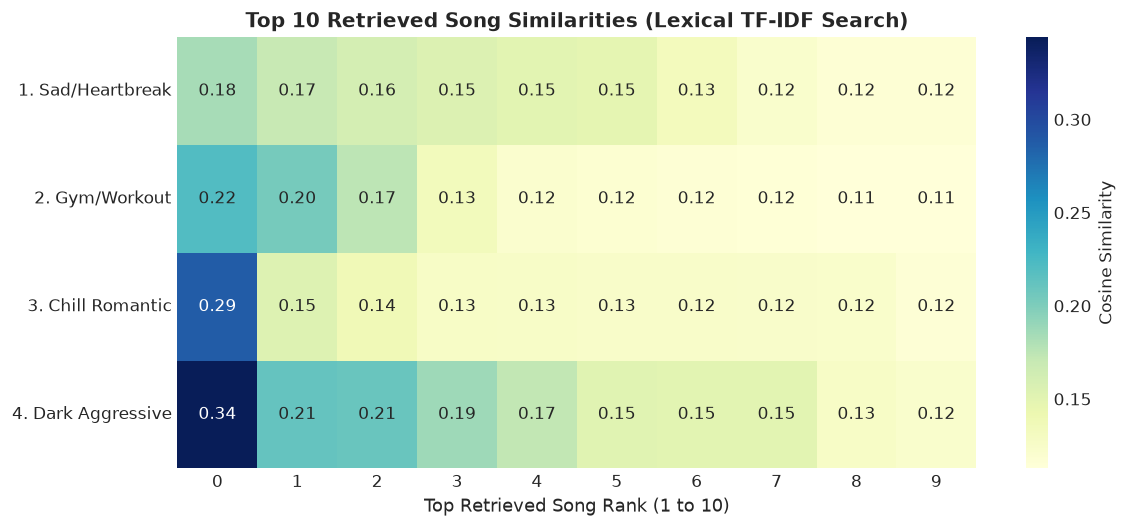

In [26]:
test_prompts = [
    'sad piano crying',
    'workout gym',
    'chill romantic r&b love',
    'raw rap hard bass'
]

# Title + Artist + Genre + first 200 words of lyrics
corpus = [
    f"{row['title']} by {row['artist']} genre: {row['genres']}. {' '.join(row['lyrics_text'].split()[:200])}"
    for _, row in df.iterrows()
]

vectorizer = TfidfVectorizer(max_features=15000, stop_words='english', ngram_range=(1, 2))
tfidf_matrix = vectorizer.fit_transform(corpus)

sim_data = []
short_labels = ['1. Sad/Heartbreak', '2. Gym/Workout', '3. Chill Romantic', '4. Dark Aggressive']

for prompt in test_prompts:
    p_vec = vectorizer.transform([prompt])
    sims = cosine_similarity(p_vec, tfidf_matrix)[0]
    top_idx = np.argsort(sims)[::-1][:10]
    sim_data.append(sims[top_idx])
    
    top_song = df.iloc[top_idx[0]]
    print(f"{prompt}")
    print(f"{top_song['title']} by {top_song['artist']} ({top_song['genres']}) - Sim: {sims[top_idx[0]]:.3f}\n")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(sim_data, annot=True, fmt='.2f', cmap='YlGnBu', yticklabels=short_labels, ax=ax,
            cbar_kws={'label': 'Cosine Similarity'})
ax.set_title('Top 10 Retrieved Song Similarities (Lexical TF-IDF Search)', fontsize=12, fontweight='bold')
ax.set_xlabel('Top Retrieved Song Rank (1 to 10)', fontsize=11)
plt.tight_layout()
plt.show()

### Conclusions

1. Truncation: 93% has more than 256 tokens (~200 words) -> We should format the data to `Title + Artist + Genre + first 200 words of lyrics`
2. Semantic Gap: For example, keyword 'sad' but sad song might not contain word 'sad' in lyric. -> Dense Embedding like BGE / MiniLM
3. Top 10 artists cover 18.4% of all songs -> We might have artist cap to not more than 2 songs of 1 artist in a playlist